# Task 4 - Regression 2: Data Preparation

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import metrics
from scipy import stats

## 2. Read data

In [2]:
df = pd.read_csv('../Data/cleaned_cars.csv')

## 3. Quick data checks

In [3]:
print('Shape:', df.shape)
print('\nFirst 5 rows:')
display(df.head())
print('\nData types:')
display(df.dtypes)
print('\nMissing values:')
display(df.isna().sum())

Shape: (6693, 22)

First 5 rows:


,raw_index,name,brand,model,year,car_age,selling_price,log_price,km_driven,fuel,...,is_trustmark,transmission,owner,owner_rank,mileage,mileage_unit,engine,max_power,torque_nm,seats
0,0,Maruti Swift Dzire VDI,Maruti,Swift,2014,6,450000,13.017003,145500,Diesel,...,0,Manual,First Owner,1,23.40,kmpl,1248,74.00,190.00,5
1,1,Skoda Rapid 1.5 TDI Ambition,Skoda,Rapid,2014,6,370000,12.821258,120000,Diesel,...,0,Manual,Second Owner,2,21.14,kmpl,1498,103.52,250.00,5
2,2,Honda City 2017-2020 EXi,Honda,City,2006,14,158000,11.970350,140000,Petrol,...,0,Manual,Third Owner,3,17.70,kmpl,1497,78.00,124.54,5
3,3,Hyundai i20 Sportz Diesel,Hyundai,i20,2010,10,225000,12.323856,127000,Diesel,...,0,Manual,First Owner,1,23.00,kmpl,1396,90.00,219.67,5
4,4,Maruti Swift VXI BSIII,Maruti,Swift,2007,13,130000,11.775290,120000,Petrol,...,0,Manual,First Owner,1,16.10,kmpl,1298,88.20,112.78,5



Data types:


raw_index          int64
name              object
brand             object
model             object
year               int64
car_age            int64
selling_price      int64
log_price        float64
km_driven          int64
fuel              object
fuel_group        object
seller_type       object
is_trustmark       int64
transmission      object
owner             object
owner_rank         int64
mileage          float64
mileage_unit      object
engine             int64
max_power        float64
torque_nm        float64
seats              int64
dtype: object


Missing values:


raw_index        0
name             0
brand            0
model            0
year             0
car_age          0
selling_price    0
log_price        0
km_driven        0
fuel             0
fuel_group       0
seller_type      0
is_trustmark     0
transmission     0
owner            0
owner_rank       0
mileage          0
mileage_unit     0
engine           0
max_power        0
torque_nm        3
seats            0
dtype: int64

## 4. Create target variable

In [4]:
df['log_price'] = np.log(df['selling_price'])

## 5. Declare model variables

In [5]:
numeric_vars = ['year', 'km_driven', 'mileage', 'engine', 'max_power']
categorical_vars = ['fuel', 'transmission', 'seller_type', 'owner', 'brand']
target_vars = ['selling_price', 'log_price']

print('Numeric:', numeric_vars)
print('Categorical:', categorical_vars)
print('Target:', target_vars)

excluded_vars = ['name', 'model', 'car_age', 'fuel_group']
print('Excluded:', excluded_vars)

Numeric: ['year', 'km_driven', 'mileage', 'engine', 'max_power']
Categorical: ['fuel', 'transmission', 'seller_type', 'owner', 'brand']
Target: ['selling_price', 'log_price']
Excluded: ['name', 'model', 'car_age', 'fuel_group']


## 6. Train/Test split

In [6]:
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42
)

print('Train shape:', train_df.shape)
print('Test shape:', test_df.shape)

Train shape: (5354, 22)
Test shape: (1339, 22)


## 7. One-hot encode categorical variables

In [7]:
numeric_vars = ['year', 'km_driven', 'mileage', 'engine', 'max_power']
categorical_vars = ['fuel', 'transmission', 'seller_type', 'owner', 'brand']

# Encode TRAIN; drop_first=True is used to avoid the dummy variable trap.
X_train = pd.get_dummies(
    train_df[numeric_vars + categorical_vars],
    columns=categorical_vars,
    drop_first=True,
    dtype=int
)

# Encode TEST independently, then reindex to the exact TRAIN predictor structure.
X_test = pd.get_dummies(
    test_df[numeric_vars + categorical_vars],
    columns=categorical_vars,
    drop_first=True,
    dtype=int
)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

y_train = train_df['log_price']
y_test = test_df['log_price']

## 8. Check encoded predictors

In [8]:
print('X_train shape:', X_train.shape)
print('X_test shape:', X_test.shape)
print('Number of predictors:', X_train.shape[1])
print('\nPredictor columns:')
print(list(X_train.columns))
print('\nMissing values in X_train:', int(X_train.isna().sum().sum()))
print('Missing values in X_test:', int(X_test.isna().sum().sum()))
print('X_train and X_test have identical columns:', X_train.columns.equals(X_test.columns))

X_train shape: (5354, 43)
X_test shape: (1339, 43)
Number of predictors: 43

Predictor columns:
['year', 'km_driven', 'mileage', 'engine', 'max_power', 'fuel_Diesel', 'fuel_LPG', 'fuel_Petrol', 'transmission_Manual', 'seller_type_Individual', 'owner_Fourth & Above Owner', 'owner_Second Owner', 'owner_Third Owner', 'brand_Ashok Leyland', 'brand_Audi', 'brand_BMW', 'brand_Chevrolet', 'brand_Daewoo', 'brand_Datsun', 'brand_Fiat', 'brand_Force', 'brand_Ford', 'brand_Honda', 'brand_Hyundai', 'brand_Isuzu', 'brand_Jaguar', 'brand_Jeep', 'brand_Kia', 'brand_Land Rover', 'brand_Lexus', 'brand_MG', 'brand_Mahindra', 'brand_Maruti', 'brand_Mercedes-Benz', 'brand_Mitsubishi', 'brand_Nissan', 'brand_Opel', 'brand_Renault', 'brand_Skoda', 'brand_Tata', 'brand_Toyota', 'brand_Volkswagen', 'brand_Volvo']

Missing values in X_train: 0
Missing values in X_test: 0
X_train and X_test have identical columns: True


## 9. Full MLR baseline on TRAIN

In [9]:
X_train_full = sm.add_constant(X_train)
X_test_full = sm.add_constant(X_test)

full_model = sm.OLS(y_train, X_train_full).fit()
print(full_model.summary())

                            OLS Regression Results                            
Dep. Variable:              log_price   R-squared:                       0.890
Model:                            OLS   Adj. R-squared:                  0.890
Method:                 Least Squares   F-statistic:                     1004.
Date:                Sat, 21 Nov 2026   Prob (F-statistic):               0.00
Time:                        12:56:47   Log-Likelihood:                -150.94
No. Observations:                5354   AIC:                             389.9
Df Residuals:                    5310   BIC:                             679.6
Df Model:                          43                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
const               

## 10. Baseline model metrics on TRAIN

In [10]:
train_predictions = full_model.predict(X_train_full)
train_rmse = np.sqrt(metrics.mean_squared_error(y_train, train_predictions))

print('R2:', full_model.rsquared)
print('Adjusted R2:', full_model.rsquared_adj)
print('AIC:', full_model.aic)
print('BIC:', full_model.bic)
print('RMSE on TRAIN (log_price):', train_rmse)

R2: 0.8904950037821643
Adjusted R2: 0.889608240159308
AIC: 389.87023457995565
BIC: 679.6366004394888
RMSE on TRAIN (log_price): 0.2488892055422623


## 11. Stepwise backward elimination

In [11]:
def backward_stepwise_aic_bic(X, y, criterion, trace=True):
    """Backward elimination using only TRAIN data."""
    features = list(X.columns)
    current = sm.OLS(y, sm.add_constant(X[features], has_constant="add")).fit()

    if trace:
        print(f"Initial {criterion}: {getattr(current, criterion):.6f}; predictors: {len(features)}")

    while features:
        current_criterion = getattr(current, criterion)
        best_candidate = None
        best_criterion = current_criterion

        for feature in features:
            candidate_features = [f for f in features if f != feature]
            candidate = sm.OLS(
                y,
                sm.add_constant(X[candidate_features], has_constant="add")
            ).fit()
            candidate_criterion = getattr(candidate, criterion)

            if candidate_criterion < best_criterion:
                best_criterion = candidate_criterion
                best_candidate = (feature, candidate_features, candidate)

        if best_candidate is None:
            break

        removed_feature, features, current = best_candidate
        if trace:
            print(
                f"Remove {removed_feature}; {criterion}: "
                f"{best_criterion:.6f}; predictors: {len(features)}"
            )

    return current, features

## 12. Fit Stepwise AIC model

In [12]:
stepwise_aic_model, aic_features = backward_stepwise_aic_bic(
    X_train,
    y_train,
    criterion="aic",
    trace=True
)

print("\nAIC Stepwise model")
print("Predictors retained:", len(aic_features))
print("AIC:", stepwise_aic_model.aic)
print("BIC:", stepwise_aic_model.bic)
print("R2:", stepwise_aic_model.rsquared)
print("Adjusted R2:", stepwise_aic_model.rsquared_adj)
print("Selected features:", aic_features)
print(stepwise_aic_model.summary())

Initial aic: 389.870235; predictors: 43


Remove brand_Daewoo; aic: 387.872798; predictors: 42


Remove brand_MG; aic: 385.884463; predictors: 41


Remove brand_Mercedes-Benz; aic: 383.910335; predictors: 40


Remove brand_BMW; aic: 381.934561; predictors: 39


Remove brand_Opel; aic: 379.977975; predictors: 38


Remove brand_Audi; aic: 378.137968; predictors: 37


Remove brand_Lexus; aic: 377.707564; predictors: 36



AIC Stepwise model
Predictors retained: 36
AIC: 377.7075642048603
BIC: 621.3747354958314
R2: 0.8904574185561881
Adjusted R2: 0.8897157347247084
Selected features: ['year', 'km_driven', 'mileage', 'engine', 'max_power', 'fuel_Diesel', 'fuel_LPG', 'fuel_Petrol', 'transmission_Manual', 'seller_type_Individual', 'owner_Fourth & Above Owner', 'owner_Second Owner', 'owner_Third Owner', 'brand_Ashok Leyland', 'brand_Chevrolet', 'brand_Datsun', 'brand_Fiat', 'brand_Force', 'brand_Ford', 'brand_Honda', 'brand_Hyundai', 'brand_Isuzu', 'brand_Jaguar', 'brand_Jeep', 'brand_Kia', 'brand_Land Rover', 'brand_Mahindra', 'brand_Maruti', 'brand_Mitsubishi', 'brand_Nissan', 'brand_Renault', 'brand_Skoda', 'brand_Tata', 'brand_Toyota', 'brand_Volkswagen', 'brand_Volvo']
                            OLS Regression Results                            
Dep. Variable:              log_price   R-squared:                       0.890
Model:                            OLS   Adj. R-squared:                  0.890
M

## 13. Fit Stepwise BIC model

In [13]:
stepwise_bic_model, bic_features = backward_stepwise_aic_bic(
    X_train,
    y_train,
    criterion="bic",
    trace=True
)

print("\nBIC Stepwise model")
print("Predictors retained:", len(bic_features))
print("AIC:", stepwise_bic_model.aic)
print("BIC:", stepwise_bic_model.bic)
print("R2:", stepwise_bic_model.rsquared)
print("Adjusted R2:", stepwise_bic_model.rsquared_adj)
print("Selected features:", bic_features)
print(stepwise_bic_model.summary())

Initial bic: 679.636600; predictors: 43


Remove brand_Daewoo; bic: 671.053565; predictors: 42


Remove brand_MG; bic: 662.479630; predictors: 41


Remove brand_Mercedes-Benz; bic: 653.919904; predictors: 40


Remove brand_BMW; bic: 645.358530; predictors: 39


Remove brand_Opel; bic: 636.816344; predictors: 38


... (8 outputs left out)

Remove brand_Kia; bic: 588.359851; predictors: 29


Remove brand_Jaguar; bic: 586.121791; predictors: 28


Remove transmission_Manual; bic: 585.381745; predictors: 27



BIC Stepwise model
Predictors retained: 27
AIC: 400.9849663302539
BIC: 585.3817446045023
R2: 0.8896096209952244
Adjusted R2: 0.8890500002229509
Selected features: ['year', 'km_driven', 'mileage', 'engine', 'max_power', 'fuel_Diesel', 'seller_type_Individual', 'owner_Fourth & Above Owner', 'owner_Second Owner', 'owner_Third Owner', 'brand_Chevrolet', 'brand_Datsun', 'brand_Fiat', 'brand_Force', 'brand_Ford', 'brand_Honda', 'brand_Hyundai', 'brand_Isuzu', 'brand_Jeep', 'brand_Mahindra', 'brand_Maruti', 'brand_Nissan', 'brand_Renault', 'brand_Skoda', 'brand_Tata', 'brand_Toyota', 'brand_Volkswagen']
                            OLS Regression Results                            
Dep. Variable:              log_price   R-squared:                       0.890
Model:                            OLS   Adj. R-squared:                  0.889
Method:                 Least Squares   F-statistic:                     1590.
Date:                Sat, 21 Nov 2026   Prob (F-statistic):               0.00


## 14. Removed predictors

In [14]:
aic_removed = [feature for feature in X_train.columns if feature not in aic_features]
bic_removed = [feature for feature in X_train.columns if feature not in bic_features]

print("Removed by AIC ({}):".format(len(aic_removed)))
print(aic_removed)
print("\nRemoved by BIC ({}):".format(len(bic_removed)))
print(bic_removed)

Removed by AIC (7):
['brand_Audi', 'brand_BMW', 'brand_Daewoo', 'brand_Lexus', 'brand_MG', 'brand_Mercedes-Benz', 'brand_Opel']

Removed by BIC (16):
['fuel_LPG', 'fuel_Petrol', 'transmission_Manual', 'brand_Ashok Leyland', 'brand_Audi', 'brand_BMW', 'brand_Daewoo', 'brand_Jaguar', 'brand_Kia', 'brand_Land Rover', 'brand_Lexus', 'brand_MG', 'brand_Mercedes-Benz', 'brand_Mitsubishi', 'brand_Opel', 'brand_Volvo']


## 15. VIF on selected models (TRAIN only)

In [15]:
def calculate_vif(X, feature_names, model_name):
    """Calculate VIF from TRAIN predictors, excluding the constant."""
    vif_X = X[feature_names].astype(float).copy()
    vif_rows = []
    numerical_warnings = []

    for i, column in enumerate(vif_X.columns):
        try:
            vif_value = variance_inflation_factor(vif_X.to_numpy(), i)
        except (TypeError, ValueError, np.linalg.LinAlgError) as exc:
            vif_value = np.inf
            numerical_warnings.append((column, str(exc)))

        vif_rows.append({
            "feature": column,
            "VIF": vif_value
        })

    vif_table = pd.DataFrame(vif_rows).sort_values(
        "VIF",
        ascending=False,
        na_position="last"
    ).reset_index(drop=True)

    finite_vif = vif_table["VIF"].replace([np.inf, -np.inf], np.nan).dropna()
    largest_feature = vif_table.iloc[0]["feature"] if len(vif_table) else "N/A"
    largest_vif = vif_table.iloc[0]["VIF"] if len(vif_table) else np.nan

    print(f"{model_name}:")
    print("Number of predictors:", len(vif_table))
    print("Largest VIF:", largest_feature, largest_vif)
    print("VIF > 5:", int((finite_vif > 5).sum()))
    print("VIF > 10:", int((finite_vif > 10).sum()))
    print("Top 10 predictors:")
    display(vif_table.head(10))

    if numerical_warnings:
        print("Numerical/identifiability warnings:")
        for feature, warning in numerical_warnings:
            print(f"- {feature}: {warning}")

    return vif_table

full_feature_names = list(X_train.columns)
aic_vif_table = calculate_vif(X_train, aic_features, "Stepwise AIC")
bic_vif_table = calculate_vif(X_train, bic_features, "Stepwise BIC")
full_vif_table = calculate_vif(X_train, full_feature_names, "Full MLR")

Stepwise AIC:
Number of predictors: 36
Largest VIF: year 455.2785663372694
VIF > 5: 12
VIF > 10: 10
Top 10 predictors:


,feature,VIF
0,year,455.278566
1,fuel_Diesel,79.618500
2,mileage,76.009615
3,fuel_Petrol,65.930290
4,engine,56.447556
5,max_power,26.608048
6,brand_Maruti,26.400874
7,transmission_Manual,17.608631
8,brand_Hyundai,14.329638
9,seller_type_Individual,10.977905


Stepwise BIC:
Number of predictors: 27
Largest VIF: year 233.66681565534947
VIF > 5: 10
VIF > 10: 7
Top 10 predictors:


,feature,VIF
0,year,233.666816
1,mileage,73.307108
2,engine,55.326761
3,max_power,24.654566
4,brand_Maruti,20.469928
5,brand_Hyundai,10.898391
6,seller_type_Individual,10.858381
7,brand_Mahindra,7.075186
8,brand_Tata,6.556181
9,fuel_Diesel,5.870459


Full MLR:
Number of predictors: 43
Largest VIF: year 2154.557593691192
VIF > 5: 26
VIF > 10: 24
Top 10 predictors:


,feature,VIF
0,year,2154.557594
1,brand_Maruti,568.154560
2,brand_Hyundai,321.140793
3,brand_Mahindra,189.820379
4,brand_Tata,177.897465
5,brand_Honda,99.538223
6,brand_Ford,95.311290
7,brand_Toyota,85.522522
8,fuel_Diesel,79.627213
9,mileage,76.665341


## 16. engine and max_power VIF/correlation

In [16]:
engine_power_pair = ["engine", "max_power"]
engine_power_correlation = train_df["engine"].corr(train_df["max_power"])
print("TRAIN correlation between engine and max_power:", engine_power_correlation)

model_sets = {
    "Full MLR": full_feature_names,
    "Stepwise AIC": aic_features,
    "Stepwise BIC": bic_features,
}
vif_tables = {
    "Full MLR": full_vif_table,
    "Stepwise AIC": aic_vif_table,
    "Stepwise BIC": bic_vif_table,
}

for model_name, features in model_sets.items():
    existing = [feature for feature in engine_power_pair if feature in features]
    print(f"{model_name}: engine/max_power present = {existing}")

    if existing:
        vif_lookup = vif_tables[model_name].set_index("feature")["VIF"]
        for feature in existing:
            print(f"  {feature} VIF: {vif_lookup.loc[feature]}")

print("engine and max_power are not automatically removed.")

TRAIN correlation between engine and max_power: 0.6814375811925355
Full MLR: engine/max_power present = ['engine', 'max_power']
  engine VIF: 56.82237889925705
  max_power VIF: 27.30973515820089
Stepwise AIC: engine/max_power present = ['engine', 'max_power']
  engine VIF: 56.44755585846149
  max_power VIF: 26.608047669795415
Stepwise BIC: engine/max_power present = ['engine', 'max_power']
  engine VIF: 55.32676146733439
  max_power VIF: 24.654565985072857
engine and max_power are not automatically removed.


## 17. Residual diagnostic plots for Stepwise AIC and BIC (TRAIN only)

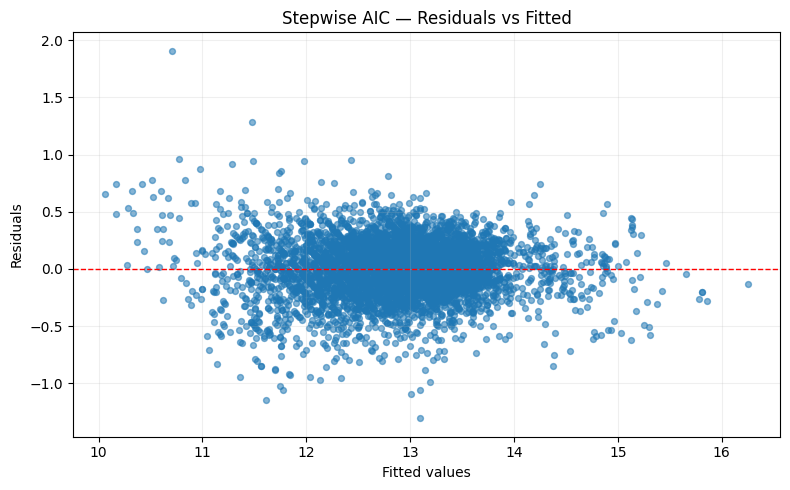

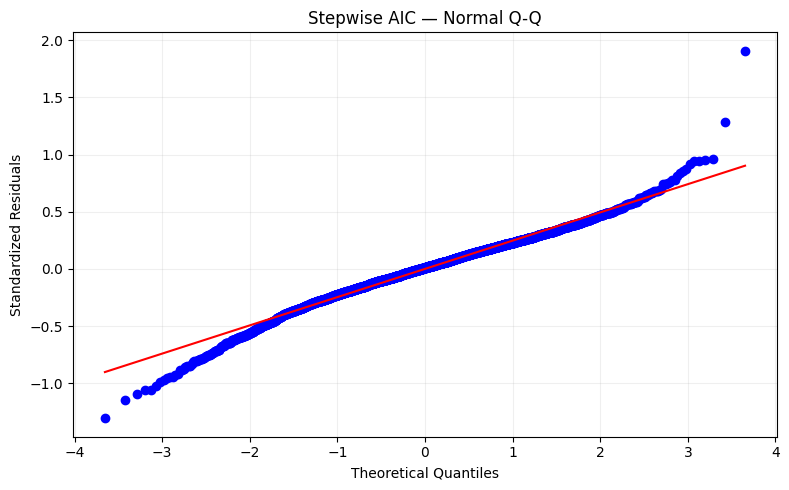

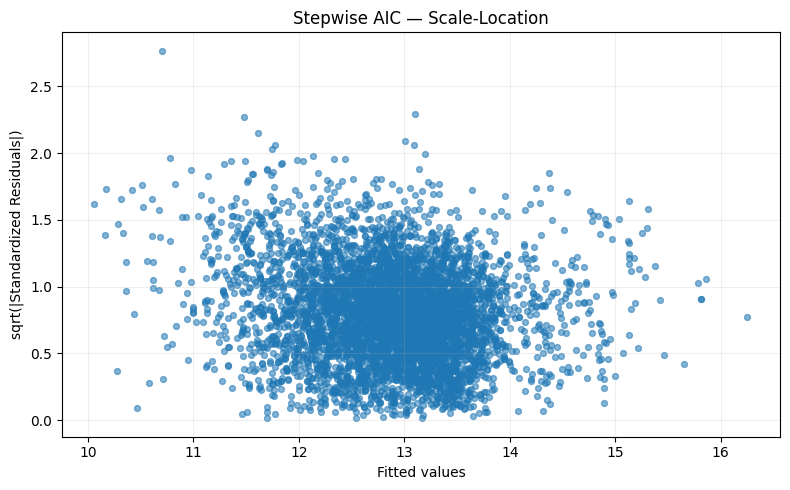

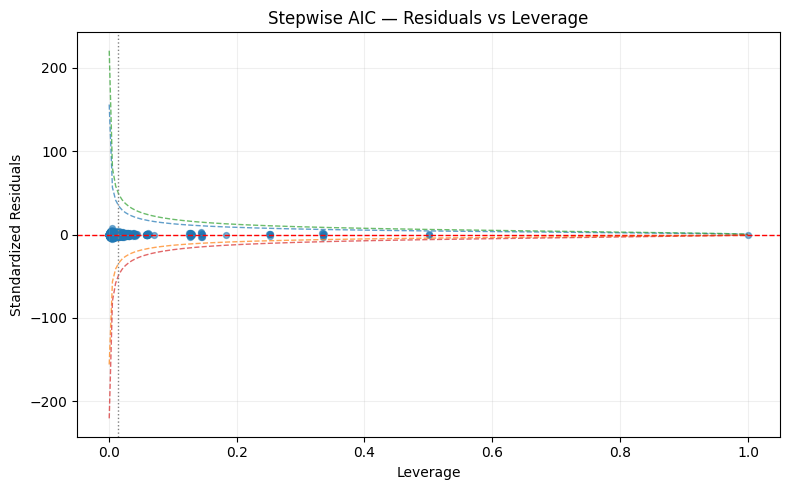

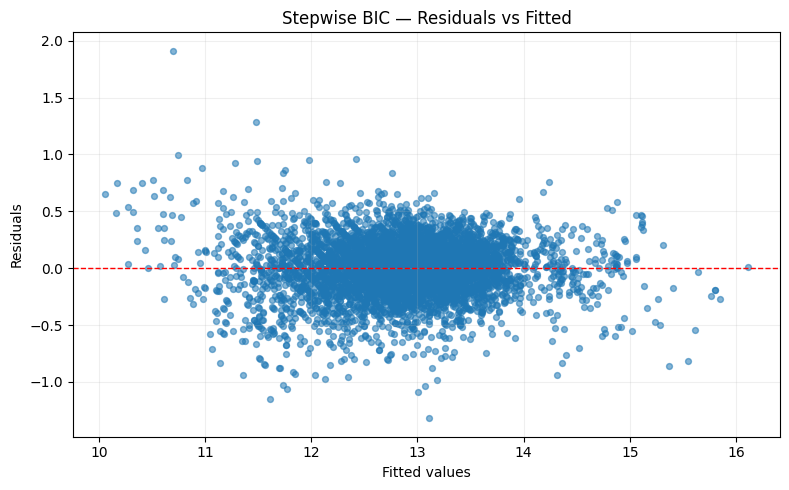

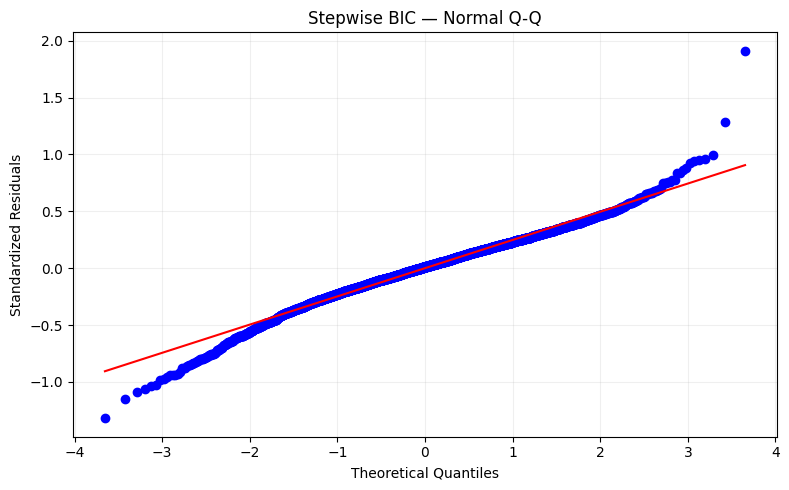

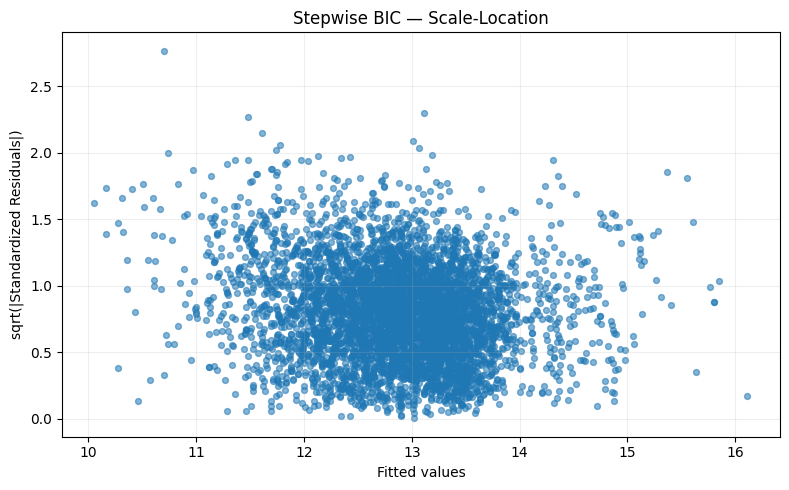

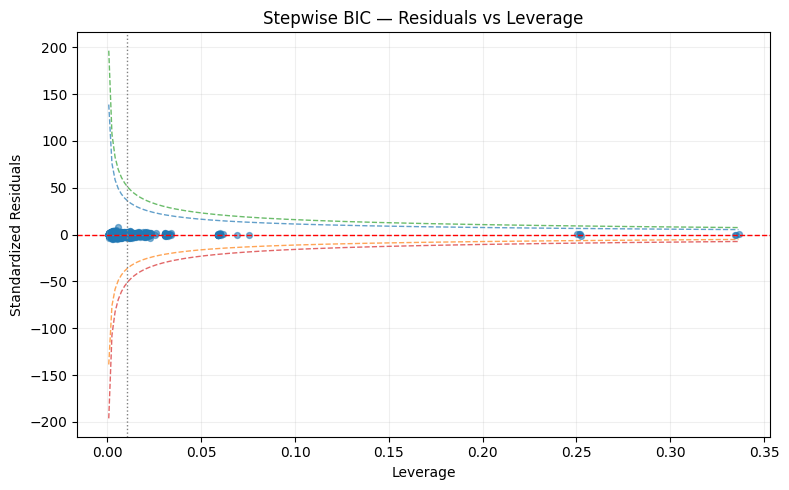

In [17]:
from pathlib import Path
from scipy import stats

output_dir = Path("../duratation result_v2/diagnostics")
output_dir.mkdir(parents=True, exist_ok=True)

def plot_residual_diagnostics(model, model_name, file_prefix):
    fitted = model.fittedvalues
    residuals = model.resid
    influence = model.get_influence()
    standardized_residuals = influence.resid_studentized_internal
    leverage = influence.hat_matrix_diag
    cooks_distance = influence.cooks_distance[0]

    # Residuals vs Fitted
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.scatter(fitted, residuals, alpha=0.55, s=18)
    ax.axhline(y=0, color="red", linestyle="--", linewidth=1)
    ax.set_title(f"{model_name} — Residuals vs Fitted")
    ax.set_xlabel("Fitted values")
    ax.set_ylabel("Residuals")
    ax.grid(alpha=0.2)
    fig.tight_layout()
    fig.savefig(output_dir / f"{file_prefix}_vs_fitted.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    # Normal Q-Q
    fig, ax = plt.subplots(figsize=(8, 5))
    stats.probplot(residuals, dist="norm", plot=ax)
    ax.set_title(f"{model_name} — Normal Q-Q")
    ax.set_xlabel("Theoretical Quantiles")
    ax.set_ylabel("Standardized Residuals")
    ax.grid(alpha=0.2)
    fig.tight_layout()
    fig.savefig(output_dir / f"{file_prefix}_qq.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    # Scale-Location
    scale_location = np.sqrt(np.abs(standardized_residuals))
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.scatter(fitted, scale_location, alpha=0.55, s=18)
    ax.set_title(f"{model_name} — Scale-Location")
    ax.set_xlabel("Fitted values")
    ax.set_ylabel("sqrt(|Standardized Residuals|)")
    ax.grid(alpha=0.2)
    fig.tight_layout()
    fig.savefig(output_dir / f"{file_prefix}_scale_location.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    # Residuals vs Leverage
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.scatter(leverage, standardized_residuals, alpha=0.55, s=18)
    ax.axhline(y=0, color="red", linestyle="--", linewidth=1)

    # Add Cook's distance contours when the leverage range is usable.
    if len(leverage) > 0:
        leverage_sorted = np.linspace(max(leverage.min() * 0.8, 1e-6), max(leverage.max(), 1e-6), 200)
        p = model.df_model + 1
        n = model.nobs
        for cook_level in (0.5, 1.0):
            residual_curve = np.sqrt(cook_level * p * (1 - leverage_sorted) / leverage_sorted)
            ax.plot(leverage_sorted, residual_curve, linestyle="--", linewidth=1, alpha=0.7)
            ax.plot(leverage_sorted, -residual_curve, linestyle="--", linewidth=1, alpha=0.7)
        ax.axvline(2 * p / n, color="gray", linestyle=":", linewidth=1)

    ax.set_title(f"{model_name} — Residuals vs Leverage")
    ax.set_xlabel("Leverage")
    ax.set_ylabel("Standardized Residuals")
    ax.grid(alpha=0.2)
    fig.tight_layout()
    fig.savefig(output_dir / f"{file_prefix}_leverage.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    return {
        "fitted": fitted,
        "residuals": residuals,
        "standardized_residuals": standardized_residuals,
        "leverage": leverage,
        "cooks_distance": cooks_distance,
    }

aic_diagnostics = plot_residual_diagnostics(
    stepwise_aic_model,
    "Stepwise AIC",
    "residual_aic"
)

bic_diagnostics = plot_residual_diagnostics(
    stepwise_bic_model,
    "Stepwise BIC",
    "residual_bic"
)

## 18. Residual tests for Stepwise AIC and BIC (TRAIN only)

In [18]:
import warnings
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson

alpha = 0.05

def run_residual_tests(model, model_name):
    residuals = model.resid
    train_exog = model.model.exog

    lm_stat, lm_pvalue, f_stat, f_pvalue = het_breuschpagan(
        residuals,
        train_exog
    )
    dw_stat = durbin_watson(residuals)

    # Run Shapiro-Wilk on all TRAIN residuals and retain any SciPy warning.
    with warnings.catch_warnings(record=True) as caught_warnings:
        warnings.simplefilter("always")
        shapiro_w, shapiro_pvalue = stats.shapiro(residuals)

    bp_conclusion = (
        "Evidence of heteroscedasticity"
        if lm_pvalue < alpha
        else "No evidence of heteroscedasticity"
    )
    shapiro_conclusion = (
        "Evidence residuals depart from normality"
        if shapiro_pvalue < alpha
        else "No evidence residuals depart from normality"
    )

    print(f"=== {model_name} ===")
    print(
        f"Breusch-Pagan: LM statistic={lm_stat:.6f}, "
        f"LM p-value={lm_pvalue:.6g}, F statistic={f_stat:.6f}, "
        f"F p-value={f_pvalue:.6g}. {bp_conclusion} (alpha={alpha})."
    )
    print(
        f"Durbin-Watson: {dw_stat:.6f}. "
        "Cross-sectional data: do not interpret this as a time-series test."
    )
    print(
        f"Shapiro-Wilk: W={shapiro_w:.6f}, "
        f"p-value={shapiro_pvalue:.6g}. {shapiro_conclusion} (alpha={alpha})."
    )
    if caught_warnings:
        print("SciPy warning(s) from Shapiro-Wilk:")
        for warning in caught_warnings:
            print(f"- {warning.message}")
    else:
        print("SciPy Shapiro-Wilk warning: none.")

    return {
        "bp_lm_stat": lm_stat,
        "bp_lm_pvalue": lm_pvalue,
        "bp_f_stat": f_stat,
        "bp_f_pvalue": f_pvalue,
        "durbin_watson": dw_stat,
        "shapiro_w": shapiro_w,
        "shapiro_pvalue": shapiro_pvalue,
        "bp_conclusion": bp_conclusion,
        "shapiro_conclusion": shapiro_conclusion,
        "shapiro_warnings": [str(warning.message) for warning in caught_warnings],
    }

aic_residual_tests = run_residual_tests(stepwise_aic_model, "Stepwise AIC")
print()
bic_residual_tests = run_residual_tests(stepwise_bic_model, "Stepwise BIC")

print("\nComparison:")
print(
    "AIC/BIC tests were run on TRAIN residuals. Compare the BP and "
    "Shapiro-Wilk conclusions above; Durbin-Watson is reported descriptively "
    "only because the observations are cross-sectional."
)

=== Stepwise AIC ===
Breusch-Pagan: LM statistic=484.726078, LM p-value=5.74605e-80, F statistic=14.702674, F p-value=2.62699e-84. Evidence of heteroscedasticity (alpha=0.05).
Durbin-Watson: 1.958732. Cross-sectional data: do not interpret this as a time-series test.
Shapiro-Wilk: W=0.984327, p-value=6.42467e-24. Evidence residuals depart from normality (alpha=0.05).
SciPy warning(s) from Shapiro-Wilk:
- scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 5354.

=== Stepwise BIC ===
Breusch-Pagan: LM statistic=458.253888, LM p-value=6.07435e-80, F statistic=18.463952, F p-value=6.20208e-84. Evidence of heteroscedasticity (alpha=0.05).
Durbin-Watson: 1.953879. Cross-sectional data: do not interpret this as a time-series test.
Shapiro-Wilk: W=0.983718, p-value=2.32072e-24. Evidence residuals depart from normality (alpha=0.05).
SciPy warning(s) from Shapiro-Wilk:
- scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 5354.

## 19. HC3 standard errors, Cook's Distance, and Leverage (TRAIN only)

In [19]:
def report_hc3_and_influence(model, model_name):
    robust_model = model.get_robustcov_results(cov_type="HC3")
    feature_names = model.model.exog_names

    hc3_table = pd.DataFrame({
        "coefficient": model.params,
        "OLS_standard_error": model.bse,
        "OLS_p_value": model.pvalues,
        "HC3_standard_error": robust_model.bse,
        "HC3_p_value": robust_model.pvalues,
    }, index=feature_names)
    hc3_table["OLS_significant_at_0.05"] = hc3_table["OLS_p_value"] < 0.05
    hc3_table["HC3_significant_at_0.05"] = hc3_table["HC3_p_value"] < 0.05
    hc3_table["Significance_changed"] = (
        hc3_table["OLS_significant_at_0.05"]
        != hc3_table["HC3_significant_at_0.05"]
    )

    influence = model.get_influence()
    cooks_distance = influence.cooks_distance[0]
    leverage = influence.hat_matrix_diag
    n = int(model.nobs)
    p = int(model.df_model)
    cooks_threshold = 4 / n
    leverage_threshold = 2 * (p + 1) / n

    train_observation_index = model.resid.index
    raw_indices = train_df.loc[train_observation_index, "raw_index"]
    cooks_table = pd.DataFrame({
        "train_index": train_observation_index,
        "raw_index": raw_indices.to_numpy(),
        "cooks_distance": cooks_distance,
    }).sort_values("cooks_distance", ascending=False).head(10)

    leverage_table = pd.DataFrame({
        "train_index": train_observation_index,
        "raw_index": raw_indices.to_numpy(),
        "leverage": leverage,
    }).sort_values("leverage", ascending=False).head(10)

    print(f"=== {model_name} ===")
    print("HC3 coefficient and standard-error comparison:")
    display(hc3_table)
    changed_count = int(hc3_table["Significance_changed"].sum())
    print(f"Predictors whose p<0.05 significance changed with HC3: {changed_count}")

    print(f"\nCook's Distance: n={n}")
    print(f"Reference threshold 4/n: {cooks_threshold:.8f}")
    print(f"Observations above threshold: {int((cooks_distance > cooks_threshold).sum())}")
    print("Top 10 observations by Cook's Distance:")
    display(cooks_table)

    print(f"\nLeverage: n={n}, p={p} predictors")
    print(f"Reference threshold 2(p+1)/n: {leverage_threshold:.8f}")
    print("Top 10 observations by leverage:")
    display(leverage_table)

    return {
        "hc3_table": hc3_table,
        "cooks_distance": cooks_distance,
        "cooks_table": cooks_table,
        "cooks_threshold": cooks_threshold,
        "leverage": leverage,
        "leverage_table": leverage_table,
        "leverage_threshold": leverage_threshold,
    }

aic_hc3_influence = report_hc3_and_influence(
    stepwise_aic_model,
    "Stepwise AIC"
)

bic_hc3_influence = report_hc3_and_influence(
    stepwise_bic_model,
    "Stepwise BIC"
)

=== Stepwise AIC ===
HC3 coefficient and standard-error comparison:


,coefficient,OLS_standard_error,OLS_p_value,HC3_standard_error,HC3_p_value,OLS_significant_at_0.05,HC3_significant_at_0.05,Significance_changed
const,-2.222834e+02,2.555688e+00,0.000000e+00,3.550125e+00,0.000000e+00,True,True,False
year,1.164605e-01,1.278179e-03,0.000000e+00,1.770155e-03,0.000000e+00,True,True,False
km_driven,-7.651634e-07,9.199128e-08,1.127512e-16,1.115606e-07,7.738806e-12,True,True,False
mileage,-4.674139e-03,1.642573e-03,4.449463e-03,1.792061e-03,9.126175e-03,True,True,False
engine,2.488743e-04,1.706718e-05,2.955754e-47,1.781150e-05,1.340375e-43,True,True,False
max_power,7.885643e-03,1.933269e-04,0.000000e+00,2.032084e-04,2.806397e-290,True,True,False
fuel_Diesel,3.732361e-01,4.129591e-02,2.191535e-19,3.198933e-02,4.455540e-31,True,True,False
fuel_LPG,1.380253e-01,6.358689e-02,3.000119e-02,5.498658e-02,1.209696e-02,True,True,False
fuel_Petrol,1.039465e-01,4.169472e-02,1.269576e-02,3.274019e-02,1.507497e-03,True,True,False
transmission_Manual,-3.676768e-02,1.504141e-02,1.454035e-02,1.453160e-02,1.142878e-02,True,True,False


Predictors whose p<0.05 significance changed with HC3: 4

Cook's Distance: n=5354
Reference threshold 4/n: 0.00074710
Observations above threshold: 256
Top 10 observations by Cook's Distance:


,train_index,raw_index,cooks_distance
1333,3463,4011,3.908404e+07
2850,448,488,1.093396e-01
1968,2495,2826,3.329684e-02
2428,981,1067,2.967877e-02
1654,4017,4787,2.865293e-02
1484,1723,1969,2.775195e-02
3117,2562,2898,2.546722e-02
3849,6676,8108,2.482754e-02
3953,3629,4253,2.161511e-02
419,4467,5349,2.146715e-02



Leverage: n=5354, p=36 predictors
Reference threshold 2(p+1)/n: 0.01382144
Top 10 observations by leverage:


,train_index,raw_index,leverage
1333,3463,4011,1.000000
5337,130,135,0.501532
5342,5578,6724,0.501532
3149,1735,1982,0.336427
2850,448,488,0.335215
2871,4082,4882,0.335183
2428,981,1067,0.334661
552,2339,2627,0.334389
3849,6676,8108,0.334082
38,6107,7336,0.252556


... (2 outputs left out)

Predictors whose p<0.05 significance changed with HC3: 0

Cook's Distance: n=5354
Reference threshold 4/n: 0.00074710
Observations above threshold: 316
Top 10 observations by Cook's Distance:


,train_index,raw_index,cooks_distance
38,6107,7336,0.018903
2190,6612,8042,0.011413
5174,4891,5836,0.008898
1613,3971,4715,0.008673
2501,39,41,0.007799
2758,4619,5511,0.007245
3149,1735,1982,0.006978
4298,4785,5726,0.006909
2822,6322,7631,0.006432
1425,4989,5962,0.005848



Leverage: n=5354, p=27 predictors
Reference threshold 2(p+1)/n: 0.01045947
Top 10 observations by leverage:


,train_index,raw_index,leverage
3149,1735,1982,0.336387
2871,4082,4882,0.335167
552,2339,2627,0.334358
38,6107,7336,0.252380
5174,4891,5836,0.251970
3132,3619,4196,0.251138
3000,6411,7746,0.250294
4035,164,170,0.075711
3411,129,134,0.069203
3265,2501,2832,0.061580


## 20. Compare and select the final model (TRAIN only)

In [1]:
comparison = pd.DataFrame([
    {
        "Model": "Stepwise AIC",
        "Predictors": 36,
        "R2 (TRAIN)": 0.8904574185561881,
        "Adjusted R2 (TRAIN)": 0.8897157347247084,
        "AIC": 377.7075642048603,
        "BIC": 621.3747354958314,
        "Max VIF": 455.278566,
        "Breusch-Pagan": "p<1e-79; heteroscedasticity",
        "Durbin-Watson": 1.958732,
        "Shapiro-Wilk": "W=0.984327; p=6.42467e-24",
        "HC3 significance changes": 4,
        "Cook's D": "max=3.9084e7*; 256 > 4/n",
        "Max leverage": 1.000000,
    },
    {
        "Model": "Stepwise BIC",
        "Predictors": 27,
        "R2 (TRAIN)": 0.8896096209952244,
        "Adjusted R2 (TRAIN)": 0.8890500002229509,
        "AIC": 400.9849663302539,
        "BIC": 585.3817446045023,
        "Max VIF": 233.666816,
        "Breusch-Pagan": "p<1e-79; heteroscedasticity",
        "Durbin-Watson": 1.953879,
        "Shapiro-Wilk": "W=0.983718; p=2.32072e-24",
        "HC3 significance changes": 0,
        "Cook's D": "max=0.018903; 316 > 4/n",
        "Max leverage": 0.336387,
    },
])
print(comparison.to_string(index=False))
print("\nSelection: Stepwise BIC.")
print(
    "Reason: fewer predictors (27 vs 36), lower BIC, lower maximum VIF, "
    "no singleton Ashok Leyland dummy with near-unit leverage, and no "
    "HC3 p<0.05 significance changes. Train R2/adjusted R2 are only "
    "slightly lower; both models show heteroscedasticity and non-normal residuals."
)
print(
    "The AIC Cook's Distance maximum is numerically unstable because "
    "raw_index 4011 has leverage approximately 1."
)

       Model  Predictors  R2 (TRAIN)  Adjusted R2 (TRAIN)        AIC        BIC    Max VIF               Breusch-Pagan  Durbin-Watson              Shapiro-Wilk  HC3 significance changes                 Cook's D  Max leverage
Stepwise AIC          36    0.890457             0.889716 377.707564 621.374735 455.278566 p<1e-79; heteroscedasticity       1.958732 W=0.984327; p=6.42467e-24                         4 max=3.9084e7*; 256 > 4/n      1.000000
Stepwise BIC          27    0.889610             0.889050 400.984966 585.381745 233.666816 p<1e-79; heteroscedasticity       1.953879 W=0.983718; p=2.32072e-24                         0  max=0.018903; 316 > 4/n      0.336387

Selection: Stepwise BIC.
Reason: fewer predictors (27 vs 36), lower BIC, lower maximum VIF, no singleton Ashok Leyland dummy with near-unit leverage, and no HC3 p<0.05 significance changes. Train R2/adjusted R2 are only slightly lower; both models show heteroscedasticity and non-normal residuals.
The AIC Cook's Distance ma

## 21. Refit final model on TRAIN and evaluate on TEST

In [1]:
final_model_name = "Stepwise BIC"
final_features = list(bic_features)

# Refit the selected specification on TRAIN only.
X_train_final = sm.add_constant(X_train[final_features], has_constant="add")
final_model = sm.OLS(y_train, X_train_final).fit()

print("Final model:", final_model_name)
print("Predictor count:", len(final_features))
print("TRAIN R2:", final_model.rsquared)
print("TRAIN adjusted R2:", final_model.rsquared_adj)
print("Intercept:", final_model.params["const"])
print("\nRegression equation (dependent variable: log_price):")
equation_terms = [
    f"({final_model.params[feature]:+.8g}) * {feature}"
    for feature in final_features
]
print(f"log_price = {final_model.params['const']:.8g} + " + " + ".join(equation_terms))
print("\nCoefficients:")
print(final_model.params.to_string())

# Evaluate once on TEST; use the TRAIN-selected predictor structure.
X_test_final = X_test.reindex(columns=final_features, fill_value=0)
X_test_final = sm.add_constant(X_test_final, has_constant="add")
predicted_log_price = final_model.predict(X_test_final)
predicted_selling_price = np.exp(predicted_log_price)
actual_selling_price = test_df["selling_price"]

test_rmse = np.sqrt(metrics.mean_squared_error(actual_selling_price, predicted_selling_price))
test_mae = metrics.mean_absolute_error(actual_selling_price, predicted_selling_price)
test_r2 = metrics.r2_score(actual_selling_price, predicted_selling_price)

print("\nTEST price comparison (first 5 rows):")
test_comparison = pd.DataFrame({
    "actual_selling_price": actual_selling_price,
    "predicted_selling_price": predicted_selling_price,
})
print(test_comparison.head().to_string())

print("\nTEST metrics on selling_price scale:")
print("RMSE:", test_rmse)
print("MAE:", test_mae)
print("R2:", test_r2)

final_results = pd.DataFrame([{
    "Final model": final_model_name,
    "Predictors": len(final_features),
    "R2 (TRAIN)": final_model.rsquared,
    "Adjusted R2 (TRAIN)": final_model.rsquared_adj,
    "RMSE TEST": test_rmse,
    "MAE TEST": test_mae,
}])
print("\nFinal results:")
print(final_results.to_string(index=False))

Final model: Stepwise BIC
Predictor count: 27
TRAIN R2: 0.8896096209952244
TRAIN adjusted R2: 0.8890500002229509
Intercept: -222.46906970105087

Regression equation (dependent variable: log_price):
log_price = -222.46907 + (+0.11658743) * year + (-8.0468168e-07) * km_driven + (-0.0053129485) * mileage + (+0.00024230111) * engine + (+0.008077402) * max_power + (+0.27061239) * fuel_Diesel + (-0.037370527) * seller_type_Individual + (-0.14663303) * owner_Fourth & Above Owner + (-0.081819075) * owner_Second Owner + (-0.11925918) * owner_Third Owner + (-0.68736846) * brand_Chevrolet + (-0.65637372) * brand_Datsun + (-0.56257806) * brand_Fiat + (-0.65574611) * brand_Force + (-0.44291982) * brand_Ford + (-0.28514138) * brand_Honda + (-0.33795485) * brand_Hyundai + (-0.47217981) * brand_Isuzu + (-0.3172342) * brand_Jeep + (-0.46118839) * brand_Mahindra + (-0.26863999) * brand_Maruti + (-0.36806972) * brand_Nissan + (-0.41718695) * brand_Renault + (-0.4124717) * brand_Skoda + (-0.76769791) * br